# Decision Trees Exercises

![DecisionTree.png](Assets/DecisionTree.png)


# Цели обучения

- Распознайте деревья решений и как их использовать для проблем классификации
- Узнайте, как определить наилучшее разделение и факторы для разделения
- Объясните сильные и слабые стороны деревьев для принятия решений
- Объясните, как деревья регрессии помогают классифицировать непрерывные значения
- Примените расширение Intel® для Scikit-learn*, чтобы использовать базовые вычислительные возможности оборудования




## Введение

Мы будем использовать набор данных качества вина для этих упражнений. Этот набор данных содержит различные химические свойства вина, такие как кислотность, сахар, pH и алкоголь. Он также содержит метрику качества (3-9, где самый высокий - лучше) и цвет (красный или белый). Имя файла - «Wine_Quality_Data.csv».

In [3]:
from __future__ import print_function
import os
data_path = ['data']

from io import StringIO
from IPython.display import Image, display

from sklearn.tree import export_graphviz
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.metrics import mean_squared_error
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.tree import DecisionTreeClassifier

try:
    from sklearnex import patch_sklearn
    patch_sklearn()
except ImportError:
    print('Intel Extension for Scikit-learn не установлен, работаем с обычным scikit-learn')

Extension for Scikit-learn* enabled (https://github.com/uxlfoundation/scikit-learn-intelex)


## Вопрос 1

* Импортируйте данные и изучите функции.
* Мы будем использовать их все для прогнозирования `color` (белого или красного), но функция цветов должна быть закодирована на целое число.

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# файл с данными лежит рядом с ноутбуком
data = pd.read_csv('data/Wine_Quality_Data.csv')
data.head()

,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality,color
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


In [5]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed_acidity         6497 non-null   float64
 1   volatile_acidity      6497 non-null   float64
 2   citric_acid           6497 non-null   float64
 3   residual_sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free_sulfur_dioxide   6497 non-null   float64
 6   total_sulfur_dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  color                 6497 non-null   str    
dtypes: float64(11), int64(1), str(1)
memory usage: 660.0 KB


In [6]:
data.describe().T

,count,mean,std,min,25%,50%,75%,max
fixed_acidity,6497.0,7.215307,1.296434,3.80000,6.40000,7.00000,7.70000,15.9000
volatile_acidity,6497.0,0.339666,0.164636,0.08000,0.23000,0.29000,0.40000,1.5800
citric_acid,6497.0,0.318633,0.145318,0.00000,0.25000,0.31000,0.39000,1.6600
residual_sugar,6497.0,5.443235,4.757804,0.60000,1.80000,3.00000,8.10000,65.8000
chlorides,6497.0,0.056034,0.035034,0.00900,0.03800,0.04700,0.06500,0.6110
free_sulfur_dioxide,6497.0,30.525319,17.749400,1.00000,17.00000,29.00000,41.00000,289.0000
total_sulfur_dioxide,6497.0,115.744574,56.521855,6.00000,77.00000,118.00000,156.00000,440.0000
density,6497.0,0.997650,0.025023,0.98711,0.99234,0.99489,0.99699,1.2026
pH,6497.0,3.218501,0.160787,2.72000,3.11000,3.21000,3.32000,4.0100
sulphates,6497.0,0.531268,0.148806,0.22000,0.43000,0.51000,0.60000,2.0000


Преобразуйте цветовую функцию в целое число. Это быстрый способ сделать это с помощью  Pandas.

In [7]:
# красное = 1, белое = 0
data['color'] = (data['color'] == 'red').astype(int)
data['color'].value_counts()

color
0    4898
1    1599
Name: count, dtype: int64

**Что сделано (Вопрос 1):** загрузили данные, посмотрели на столбцы и типы (`info`, `describe`). В датасете 6497 вин и 13 столбцов, пропусков нет, все признаки числовые, кроме `color`. Столбец `color` был строкой, поэтому закодировали его числами: красное вино = 1, белое = 0. Видно, что белых вин заметно больше, чем красных.

## Вопрос 2

* Используйте `StratifiedShuffleSplit` для разделения данных на наборы поездов и тестов, которые стратифицированы по качеству вина. Если возможно, сохраните индексы доли для вопроса 5 ниже.
* Проверьте процентный состав каждого уровня качества для наборов данных о поезде и тестовых данных.

In [8]:
# все столбцы, кроме color, - признаки; color - целевая переменная
feature_cols = [x for x in data.columns if x != 'color']

# стратификация по качеству вина
strat_shuf_split = StratifiedShuffleSplit(n_splits=1, test_size=0.3, random_state=42)

# индексы сохраняем, они понадобятся в вопросе 5
train_idx, test_idx = next(strat_shuf_split.split(data[feature_cols], data['quality']))

X_train = data.loc[train_idx, feature_cols]
y_train = data.loc[train_idx, 'color']

X_test = data.loc[test_idx, feature_cols]
y_test = data.loc[test_idx, 'color']

print(X_train.shape, X_test.shape)

(4547, 12) (1950, 12)


Теперь проверьте процентную долю каждого уровня качества в обучающем и тестовом наборах данных. Как видно ниже, набор данных в основном состоит из белого вина.

In [9]:
quality_share = pd.DataFrame({
    'train, %': X_train['quality'].value_counts(normalize=True) * 100,
    'test, %': X_test['quality'].value_counts(normalize=True) * 100
}).sort_index().round(2)
quality_share

,"train, %","test, %"
quality,,
3,0.46,0.46
4,3.32,3.33
5,32.90,32.92
6,43.66,43.64
7,16.60,16.62
8,2.97,2.97
9,0.09,0.05


In [10]:
# доля красных (1) и белых (0) вин в обучающей и тестовой выборках
pd.DataFrame({
    'train, %': y_train.value_counts(normalize=True) * 100,
    'test, %': y_test.value_counts(normalize=True) * 100
}).round(2)

,"train, %","test, %"
color,,
0,74.55,77.33
1,25.45,22.67


**Что сделано (Вопрос 2):** разбили данные на обучающую (70%) и тестовую (30%) выборки с помощью `StratifiedShuffleSplit`, стратифицируя по `quality`. Индексы `train_idx` и `test_idx` сохранили, чтобы использовать их в вопросе 5. По таблице видно, что доли каждого уровня качества в обучающей и тестовой выборках почти одинаковые, то есть стратификация сработала. Доля белых вин в обеих выборках тоже примерно одинаковая.

## Вопрос 3

* Постройте классификатор на основе дерева решений без ограничений на максимальную глубину, количество признаков или количество листьев.
* Определите, сколько узлов присутствует в этом (очень большом) дереве и какова его глубина.
* Используя это дерево, оцените погрешность прогнозирования на обучающем и тестовом наборах данных. Как вы думаете, что здесь происходит, исходя из различий в погрешности прогнозирования?

In [11]:
# дерево без ограничений
dt = DecisionTreeClassifier(random_state=42)
dt = dt.fit(X_train, y_train)

Количество узлов и максимальная фактическая глубина.

In [12]:
print('Количество узлов:', dt.tree_.node_count)
print('Максимальная глубина:', dt.tree_.max_depth)

Количество узлов: 143
Максимальная глубина: 20


In [13]:
def measure_error(y_true, y_pred, label):
    return pd.Series({'accuracy': accuracy_score(y_true, y_pred),
                      'precision': precision_score(y_true, y_pred),
                      'recall': recall_score(y_true, y_pred),
                      'f1': f1_score(y_true, y_pred)},
                     name=label)

y_train_pred = dt.predict(X_train)
y_test_pred = dt.predict(X_test)

train_test_full_error = pd.concat([measure_error(y_train, y_train_pred, 'train'),
                                   measure_error(y_test, y_test_pred, 'test')],
                                  axis=1)
train_test_full_error

,train,test
accuracy,0.999560,0.986154
precision,0.999136,0.974828
recall,0.999136,0.963801
f1,0.999136,0.969283


Дерево решений демонстрирует чуть более точные прогнозы на обучающих данных, чем на тестовых, что свидетельствует о (незначительной) переобученности. Также обратите внимание на идеальный показатель воспроизводимости для обучающих данных. Во многих случаях разница в точности прогнозов бывает даже больше, чем показано здесь.

**Что сделано (Вопрос 3):** обучили `DecisionTreeClassifier` без ограничений по глубине, признакам и листьям. Такое дерево растёт, пока не разделит обучающую выборку полностью, поэтому получилось много узлов и большая глубина. Считали accuracy, precision, recall и f1 на обучающей и тестовой выборках. На обучающей выборке все метрики почти равны 1.0 (дерево «выучило» данные наизусть), на тестовой чуть ниже (accuracy около 0.986) - это небольшое переобучение.

## Вопрос 4

* С помощью сетчатого поиска с перекрестной валидацией найдите дерево решений, которое демонстрирует хорошие результаты на тестовом наборе данных. Присвойте этой модели дерева решений другое имя переменной, чем в вопросе 3, чтобы обе модели можно было использовать в вопросе 6.
* Определите количество узлов и глубину этого дерева.
* Рассчитайте погрешности на обучающем и тестовом наборах данных, как и ранее, и сравните их с погрешностями дерева из вопроса 3.

In [14]:
# перебираем глубину и число признаков, максимум глубины - глубина дерева из вопроса 3
param_grid = {'max_depth': range(1, dt.tree_.max_depth + 1, 2),
              'max_features': range(1, len(X_train.columns) + 1)}

GR = GridSearchCV(DecisionTreeClassifier(random_state=42),
                  param_grid=param_grid,
                  scoring='accuracy',
                  n_jobs=-1,
                  cv=5)

GR = GR.fit(X_train, y_train)
GR.best_params_

{'max_depth': 9, 'max_features': 8}

In [15]:
# лучшая модель под другим именем, чтобы не потерять dt из вопроса 3
dt_best = GR.best_estimator_

Количество узлов и максимальная глубина дерева.

In [16]:
print('Количество узлов:', dt_best.tree_.node_count)
print('Максимальная глубина:', dt_best.tree_.max_depth)

Количество узлов: 105
Максимальная глубина: 9


In [17]:
y_train_pred_gr = dt_best.predict(X_train)
y_test_pred_gr = dt_best.predict(X_test)

train_test_gr_error = pd.concat([measure_error(y_train, y_train_pred_gr, 'train'),
                                 measure_error(y_test, y_test_pred_gr, 'test')],
                                axis=1)
train_test_gr_error

,train,test
accuracy,0.997581,0.985641
precision,0.999129,0.968326
recall,0.991357,0.968326
f1,0.995228,0.968326


Ошибки тестирования получились практически такими же, как у полного дерева из вопроса 3 (разница в тысячных долях), при этом новое дерево заметно проще: меньше узлов и почти вдвое меньшая глубина. Таким образом, можно сделать вывод, что в предыдущем примере имело место переобучение, но лишь в незначительной степени.

**Что сделано (Вопрос 4):** с помощью `GridSearchCV` (5-кратная кросс-валидация, метрика accuracy) подобрали `max_depth` и `max_features`. Лучшую модель сохранили в `dt_best`, чтобы `dt` из вопроса 3 остался нетронутым. Получилось более простое дерево (меньше узлов, глубина 9 вместо 20), а качество на тесте практически такое же. Это значит, что дерево из вопроса 3 было избыточно сложным, а сложность почти не давала выигрыша на новых данных.

## Вопрос 5

* Снова разделите данные на части `X` и `y`, на этот раз с `residual_sugar` в качестве прогнозируемых (`y`) данных. *Примечание:* если индексы были сохранены из результатов `StratifiedShuffleSplit` в вопросе 2, их можно использовать повторно для разделения данных.
* Используя поиск по сетке с перекрестной валидацией, найдите модель **регрессии** на основе дерева решений, которая хорошо работает на тестовом наборе данных.
* Оцените погрешности на обучающем и тестовом наборах данных с помощью среднеквадратичной ошибки.
* Постройте график, на котором будут отображены фактические *и* прогнозируемые значения остаточного сахара.

In [18]:
# теперь целевая переменная - residual_sugar, признаки - все остальные столбцы
feature_cols_reg = [x for x in data.columns if x != 'residual_sugar']

# используем сохранённые индексы из вопроса 2
X_train_reg = data.loc[train_idx, feature_cols_reg]
y_train_reg = data.loc[train_idx, 'residual_sugar']

X_test_reg = data.loc[test_idx, feature_cols_reg]
y_test_reg = data.loc[test_idx, 'residual_sugar']

param_grid_reg = {'max_depth': range(1, 16),
                  'max_features': range(1, len(feature_cols_reg) + 1)}

GR_reg = GridSearchCV(DecisionTreeRegressor(random_state=42),
                      param_grid=param_grid_reg,
                      scoring='neg_mean_squared_error',
                      n_jobs=-1,
                      cv=5)

GR_reg = GR_reg.fit(X_train_reg, y_train_reg)
GR_reg.best_params_

{'max_depth': 13, 'max_features': 10}

Количество узлов и максимальная глубина дерева. В этом дереве много узлов, что неудивительно, учитывая непрерывный характер данных.

In [19]:
dt_reg = GR_reg.best_estimator_
print('Количество узлов:', dt_reg.tree_.node_count)
print('Максимальная глубина:', dt_reg.tree_.max_depth)

Количество узлов: 2701
Максимальная глубина: 13


Ошибка на обучающем и тестовом наборах данных. Поскольку речь идет о непрерывных величинах, мы будем использовать среднеквадратичную ошибку.

In [20]:
y_train_reg_pred = dt_reg.predict(X_train_reg)
y_test_reg_pred = dt_reg.predict(X_test_reg)

print('MSE на обучающей выборке:', round(mean_squared_error(y_train_reg, y_train_reg_pred), 3))
print('MSE на тестовой выборке:', round(mean_squared_error(y_test_reg, y_test_reg_pred), 3))

MSE на обучающей выборке: 0.291
MSE на тестовой выборке: 2.862


График, отражающий соотношение фактического и прогнозируемого остаточного содержания сахара.

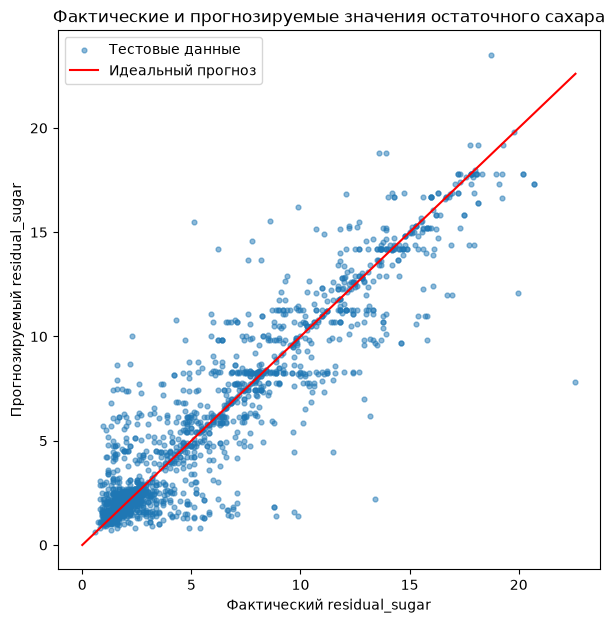

In [21]:
plt.figure(figsize=(7, 7))
plt.scatter(y_test_reg, y_test_reg_pred, s=12, alpha=0.5, label='Тестовые данные')

# идеальный прогноз - прямая y = x
lims = [0, y_test_reg.max()]
plt.plot(lims, lims, color='red', label='Идеальный прогноз')

plt.xlabel('Фактический residual_sugar')
plt.ylabel('Прогнозируемый residual_sugar')
plt.title('Фактические и прогнозируемые значения остаточного сахара')
plt.legend()
plt.show()

**Что сделано (Вопрос 5):** снова разбили данные, но теперь целевой переменной стал `residual_sugar` (непрерывная величина), а признаками - все остальные столбцы, включая `color` и `quality`. Для разбиения использовали сохранённые индексы из вопроса 2. С помощью `GridSearchCV` подобрали параметры `DecisionTreeRegressor` по среднеквадратичной ошибке. Сравнили MSE на обучающей и тестовой выборках и построили график «факт - прогноз»: чем ближе точки к красной прямой, тем точнее прогноз.

## Вопрос 6 *(Необязательный)*

Этот вопрос является необязательным, так как для его решения требуется дополнительная программа командной строки (GraphViz) и библиотека Python (PyDotPlus). GraphViz можно установить с помощью менеджера пакетов в Linux и Mac. Для установки библиотеки PyDotPlus можно использовать либо `pip`, либо `conda` (`conda install -c conda-forge pydotplus`).

После установки этих программ:

* Создайте визуализацию дерева решений из вопроса 3, в котором предсказывался цвет вина, а количество признаков и/или разбиений не ограничено.
* Создайте визуализацию дерева решений из вопроса 4, в котором предсказывался цвет вина, но для нахождения оптимальной глубины и количества признаков использовался поиск по сетке.

Дерево решений из вопроса 5, скорее всего, будет иметь слишком много узлов для визуализации.